In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("../data/prescription_large.csv", encoding='ISO-8859-9')

X = df.drop("Toplam Ilac Harcamasi", axis=1)
y = df["Toplam Ilac Harcamasi"]

In [4]:
df = df.rename(columns={
    "Yil": "year",
    "Ay": "month",
    "Recete Sayisi": "prescription_count",
    "Ortalama Recete Bedeli": "avg_prescription_cost",
    "Toplam Ilac Harcamasi": "total_drug_cost",
    "Markali İlac Orani": "brand_ratio",
    "Saglik Enflasyonu": "health_inflation"
})

In [5]:
features = [
    "year", "month", "prescription_count",
    "avg_prescription_cost", "brand_ratio", "health_inflation"
]

target = "total_drug_cost"

X = df[features]
y = df[target]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [7]:
#Preprocessing
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), features)])

In [8]:
#Modeller
models = {
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=10, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42
    ),
    "MLP Regressor": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        max_iter=1000,
        early_stopping=True,
        random_state=42
    )
}

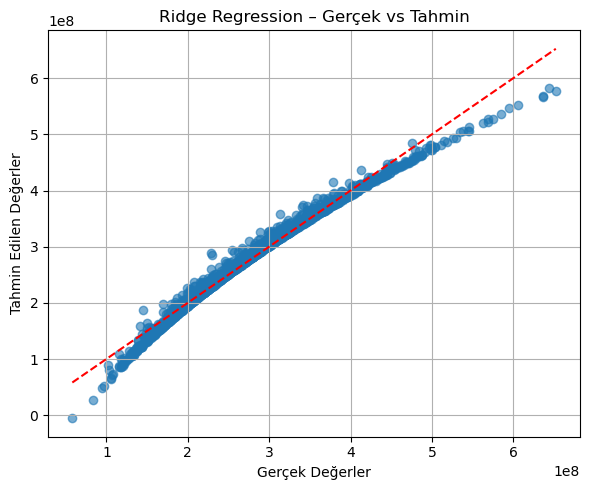

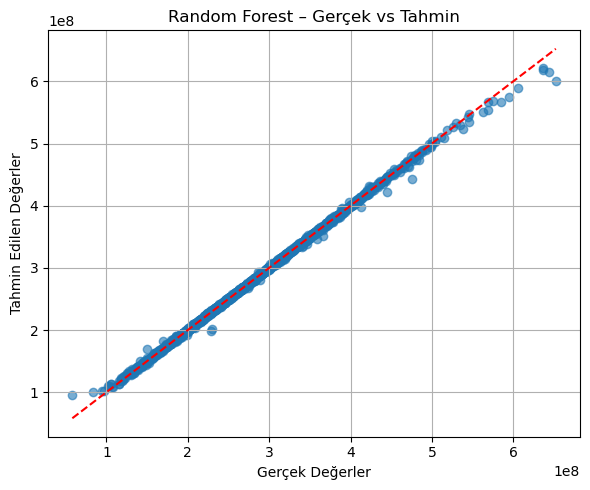

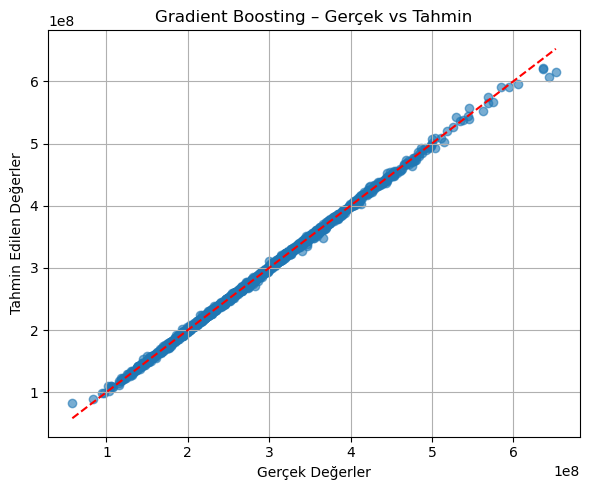

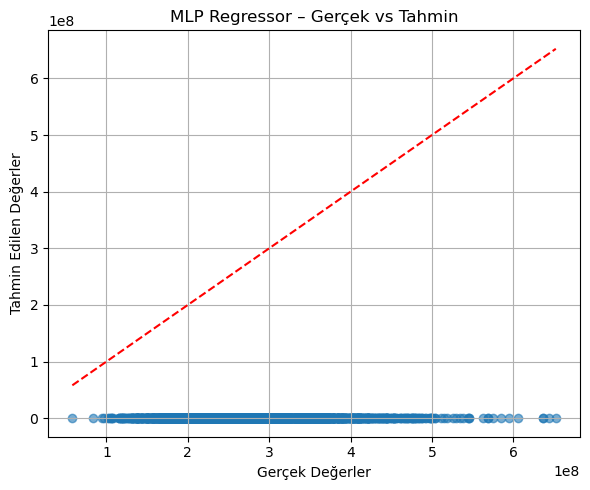

In [9]:
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred)
    })
    
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r')
    plt.xlabel("Gerçek Değerler")
    plt.ylabel("Tahmin Edilen Değerler")
    plt.title(f"{name} – Gerçek vs Tahmin")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [10]:
results_df = pd.DataFrame(results)
print(results_df)

               Model   R2 Score          RMSE           MAE
0   Ridge Regression   0.984186  1.056932e+07  6.874703e+06
1      Random Forest   0.998889  2.801545e+06  1.255427e+06
2  Gradient Boosting   0.999043  2.600388e+06  1.659674e+06
3      MLP Regressor -10.866486  2.895295e+08  2.770618e+08


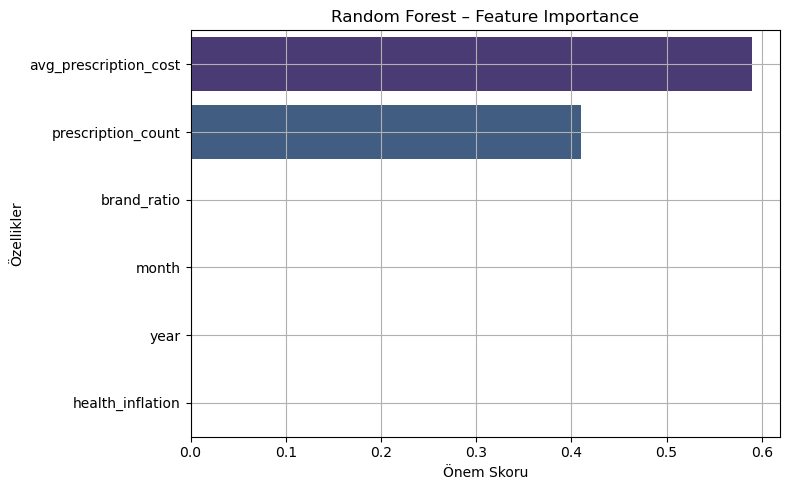

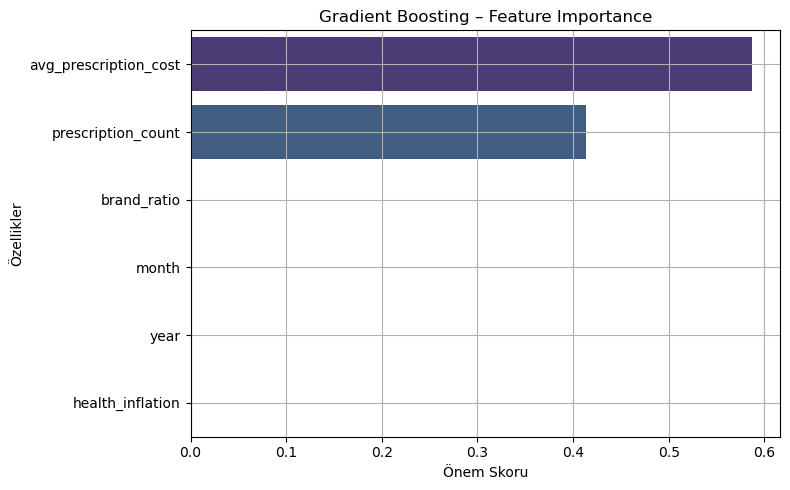

In [11]:
# Özellik isimleri (ön işlemden sonra ölçeklenen)
feature_names = features  # çünkü sadece sayısal değişkenler vardı, OneHot yok

# Modeller ve isimleri
interpretable_models = {
    "Random Forest": models["Random Forest"],
    "Gradient Boosting": models["Gradient Boosting"]
}

# Her model için ayrı ayrı importance çıkar ve görselleştir
for name, model in interpretable_models.items():
    # Pipeline tekrar kurulmalı (preprocessing dahil)
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])
    
    # Eğit
    pipeline.fit(X_train, y_train)
    
    # Feature importances
    importances = pipeline.named_steps["regressor"].feature_importances_
    
    # DataFrame oluştur
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(by="Importance", ascending=False)
    
    # Barplot çiz
    plt.figure(figsize=(8, 5))
    sns.barplot(
    x="Importance",
    y="Feature",
    hue="Feature",
    dodge=False,
    legend=False,
    data=importance_df,
    palette="viridis"
)
    plt.title(f"{name} – Feature Importance")
    plt.xlabel("Önem Skoru")
    plt.ylabel("Özellikler")
    plt.tight_layout()
    plt.grid(True)
    plt.show()

In [14]:
#save models
import os
from joblib import dump
# Ridge Regression
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0, random_state=42))
])
ridge_pipeline.fit(X_train, y_train)
dump(ridge_pipeline, "../models/prescription_ridge.pkl")

# Random Forest
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200, max_depth=10, random_state=42
    ))
])
rf_pipeline.fit(X_train, y_train)
dump(rf_pipeline, "../models/prescription_rf.pkl")

# Gradient Boosting
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42
    ))
])
gb_pipeline.fit(X_train, y_train)
dump(gb_pipeline, "../models/prescription_gb.pkl")

# MLP Regressor
mlp_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=1000,
        early_stopping=True,
        random_state=42
    ))
])
mlp_pipeline.fit(X_train, y_train)
dump(mlp_pipeline, "../models/prescription_mlp.pkl")

['../models/prescription_mlp.pkl']